> **Telecommunication Lab Exam | Experiment 6**  
> Based on *Telecommunication-Lab.pdf*, PDF pages 18–20.  
> **Use:** Read the theory → run the two code cells → identify the output → practice the viva answers.  
> **Software:** Python 3, Jupyter/Colab, `numpy`, `matplotlib`. **Only Exp 1 optionally needs `scipy`.**


# Experiment 6 — Direct Sequence Spread Spectrum (DSSS)

**Aim (manual):** Implement Direct Sequence Spread Spectrum. The manual uses a 7-chip PN sequence followed by BPSK modulation.

## 1. Theory / working principle

**DSSS** spreads each low-rate data bit into several faster **chips** by multiplying the polar data with a pseudonoise (**PN**) sequence. The wider-band signal is then BPSK-modulated onto a carrier.

**Transmitter (manual diagram):** Binary data → polar NRZ encoder → multiply by PN code → BPSK modulator with a carrier → DSSS signal.  
**Receiver (manual diagram):** Received signal → coherent detector / local carrier → multiply by synchronized local PN sequence → integrate / decide bit.

Map binary data and PN bits to polar levels:

$$d_k=2b_k-1,\quad p_j=2c_j-1 \qquad (0\mapsto-1,\;1\mapsto+1)$$

**Spread chip value** for data bit $k$ and chip index $j$:

$$m_{k,j}=d_k p_j$$

**BPSK-modulated DSSS waveform:**

$$s(t)=m(t)\cos(2\pi f_c t)$$

With $L$ chips per data bit, the processing gain for the ideal equal-bandwidth approximation is:

$$G_p=L,\qquad G_{p,\mathrm{dB}}=10\log_{10}L$$

DSSS makes the transmitted signal occupy a wider spectrum and supports interference resistance when a receiver has the correct synchronized PN code.


## 2. Lab-manual input and example

The manual specifies:

- Input data: **`1 0 1`**
- PN sequence: **`0 0 1 0 1 1 1`** (length $L=7$)
- Polar PN: **`-1 -1 +1 -1 +1 +1 +1`**
- BPSK carrier: **$f_c=10$ cycles per bit interval**, as used by the manual's time normalization.

**How the bits spread:**

- A `1` gives the polar PN sequence unchanged.
- A `0` inverts every PN chip.
- A `1` gives the PN sequence unchanged again.

$$G_{p,\mathrm{dB}} = 10\log_{10}(7)\approx8.45\,\mathrm{dB}$$

**What is added beyond the manual's MATLAB code?** The manual shows the baseband, carrier and BPSK DSSS plots. The following Python demo also implements an **ideal synchronized despreading check**, consistent with the receiver block diagram, to print the recovered bits.


## 3. Runnable Python implementation

**Run the next cell** to compute the signal and print essential results. The following cell draws the output waveforms. Use **Run All** to execute both in order.

In [1]:
"""Experiment 6: DSSS with a 7-chip PN code and BPSK carrier."""
import numpy as np
import matplotlib.pyplot as plt

data = np.array([1, 0, 1])
pn = np.array([0, 0, 1, 0, 1, 1, 1])
L, samples = len(pn), 40
pn_polar = 2 * pn - 1
spread = np.concatenate([(2*b-1) * pn_polar for b in data])
baseband = np.repeat(spread, samples)
t = np.arange(len(baseband)) / (L * samples)
carrier = np.cos(2 * np.pi * 10 * t)
tx = baseband * carrier

# Despread and correlate using synchronized PN and carrier
pn_samples = np.repeat(np.tile(pn_polar, len(data)), samples)
received = []
for k in range(len(data)):
    sl = slice(k*L*samples, (k+1)*L*samples)
    received.append(int(np.sum(tx[sl]*carrier[sl]*pn_samples[sl]) > 0))
print('Sent bits:    ', data)
print('Received bits:', received)
print(f'Processing gain: {L} = {10*np.log10(L):.2f} dB')

Sent bits:     [1 0 1]
Received bits: [1, 0, 1]
Processing gain: 7 = 8.45 dB


In [2]:
assert received == data.tolist()
assert len(spread) == len(data)*len(pn)
print('Checks passed: recovered bits match, 7 chips/bit')

Checks passed: recovered bits match, 7 chips/bit


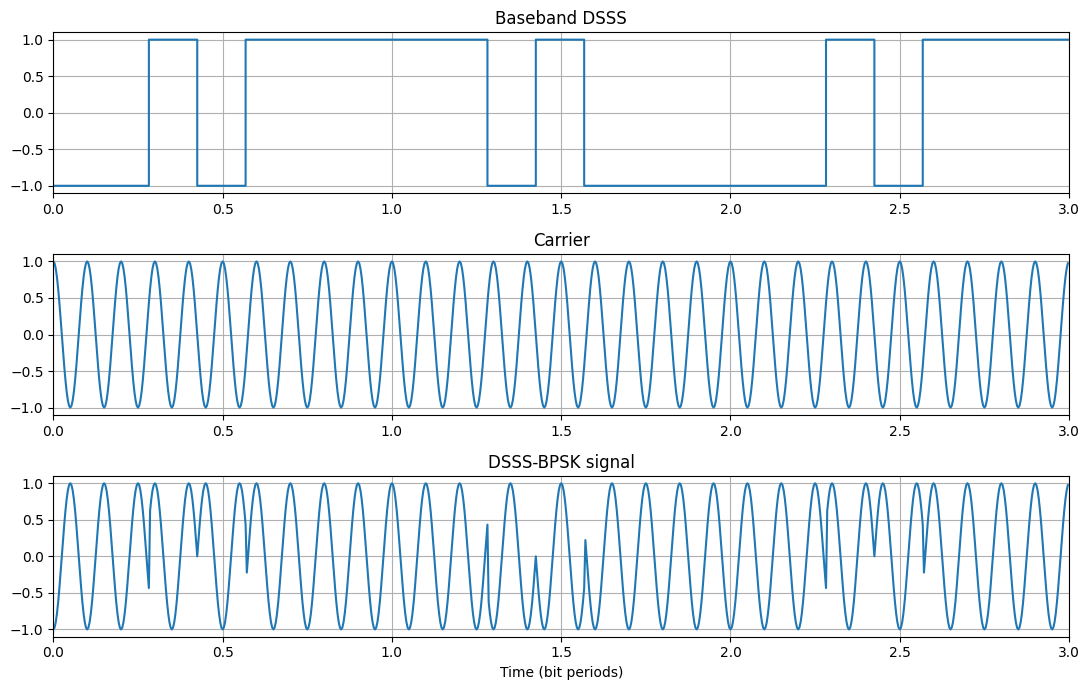

In [3]:
fig, ax = plt.subplots(3, 1, figsize=(11, 7))
ax[0].step(t, baseband); ax[0].set_title('Baseband DSSS')
ax[1].plot(t, carrier); ax[1].set_title('Carrier')
ax[2].plot(t, tx); ax[2].set_title('DSSS-BPSK signal')
for a in ax: a.grid(True); a.set_xlim(0, len(data))
ax[-1].set_xlabel('Time (bit periods)')
fig.tight_layout();
plt.show()

## 4. Expected output and interpretation

- Plot 1, **Baseband DSSS**: the polar value may change multiple times inside one original data bit because of the 7-chip PN code.
- Plot 2, **Carrier**: a sinusoidal carrier of constant frequency.
- Plot 3, **DSSS-BPSK**: carrier phase changes according to the spread chip signs.
- Printed result: sent bits **`[1 0 1]`** and recovered bits **`[1, 0, 1]`** (ideal synchronized receiver).
- Processing gain: **7** or about **8.45 dB**.

**Result to write:** The binary input sequence was spread with the PN sequence and modulated using BPSK, producing a DSSS signal. Under ideal receiver synchronization, the original sequence was recovered.

## 5. Viva — short answers

**Q1. What is DSSS?** A spread-spectrum technique that multiplies data with a faster PN chip sequence.  
**Q2. What is a chip?** One element of the higher-rate spreading sequence.  
**Q3. Why use PN code?** For controlled spreading and synchronized despreading.  
**Q4. Data bit vs chip?** One data bit is represented by several PN chips.  
**Q5. What is a spreading factor here?** $L=7$ chips per bit.  
**Q6. How does the receiver recover data?** It uses a synchronized local PN sequence and coherent detection/correlation.  
**Q7. What if PN sequences are not synchronized?** Despreading and data recovery degrade.  
**Q8. DSSS vs FHSS?** DSSS spreads through code multiplication; FHSS changes carrier frequency over time.

**Practice:** Explain why an input `0` produces the *negative* of the PN pattern.
